# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance

**Nama:** Muhammad Farid Wijdan  
**NRP:** 5054251042  
**Dataset:** Credit Card Fraud Detection (MLG-ULB) — [Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)  

Tujuan: membandingkan Random Forest baseline, class-weighted Random Forest, dan Random Forest dengan SMOTE untuk deteksi fraud. Data mentah tidak disertakan di repository; simpan `creditcard.csv` di folder ini sebelum menjalankan notebook.

## 1. Import library dan muat dataset
Jalankan `pip install -r requirements.txt` bila dependency belum tersedia. Dataset harus berada di folder `tugas-ensemble/` dan tidak di-commit karena ukurannya lebih dari 100 MB.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

DATA_PATH = Path('creditcard.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Unduh creditcard.csv dari Kaggle dan letakkan di folder tugas-ensemble.')
df = pd.read_csv(DATA_PATH)
assert 'Class' in df.columns, 'Kolom target Class tidak ditemukan.'
X = df.drop(columns='Class')
y = df['Class']
print('Shape:', df.shape)
display(df.head())
df.info()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

## 2. Eksplorasi distribusi kelas
Dataset sangat tidak seimbang. Accuracy saja dapat menyesatkan: model yang selalu memprediksi kelas mayoritas akan terlihat akurat, tetapi gagal mendeteksi fraud. Karena itu, evaluasi utama memakai precision, recall, F1, ROC-AUC dan PR-AUC.

,transaksi,persentase
Class,,
0,284315,99.827251
1,492,0.172749


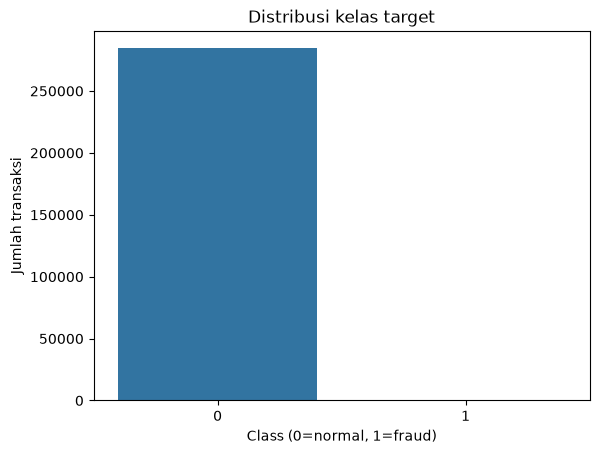

In [2]:
counts = y.value_counts().sort_index()
summary = pd.DataFrame({'transaksi': counts, 'persentase': counts / len(y) * 100})
display(summary)
ax = sns.barplot(x=counts.index.astype(str), y=counts.values)
ax.set(xlabel='Class (0=normal, 1=fraud)', ylabel='Jumlah transaksi', title='Distribusi kelas target')
plt.show()

## 3. Split data tanpa kebocoran
Pemisahan dilakukan secara stratified 80:20. SMOTE hanya diterapkan di dalam pipeline saat `fit` pada data latih; data uji tetap mempertahankan distribusi aslinya.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Fraud test:', int(y_test.sum()), '/', len(y_test))

Train: (227845, 30) Test: (56962, 30)
Fraud test: 98 / 56962


## 4. Model ensemble
Ketiga model memakai Random Forest (100 pohon, seed 42). Model kedua menggunakan `balanced_subsample`; model ketiga melakukan oversampling SMOTE hanya terhadap fold training.

In [4]:
models = {
    'Random Forest (baseline)': RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    'Random Forest (class_weight=balanced)': RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1,
        class_weight='balanced_subsample'
    ),
    'SMOTE + Random Forest': Pipeline([
        ('smote', SMOTE(random_state=42)),
        ('model', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
    ])
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    results.append({
        'Model': name,
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, score),
        'PR-AUC': average_precision_score(y_test, score),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })
results_df = pd.DataFrame(results).set_index('Model')
display(results_df.round(4))

,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
Model,,,,,,,,,
Random Forest (baseline),0.9412,0.8163,0.8743,0.9630,0.8734,56859,5,18,80
Random Forest (class_weight=balanced),0.9600,0.7347,0.8324,0.9529,0.8597,56861,3,26,72
SMOTE + Random Forest,0.8351,0.8265,0.8308,0.9644,0.8747,56848,16,17,81


## 5. Confusion matrix dan interpretasi
False negative (FN) adalah transaksi fraud yang terlewat; false positive (FP) adalah transaksi normal yang ditandai fraud. Pada konteks deteksi fraud, FN berpotensi menyebabkan kerugian, sedangkan FP menambah beban pemeriksaan. Ambang klasifikasi default 0.5 belum tentu optimal; pemilihan threshold harus mempertimbangkan biaya bisnis.

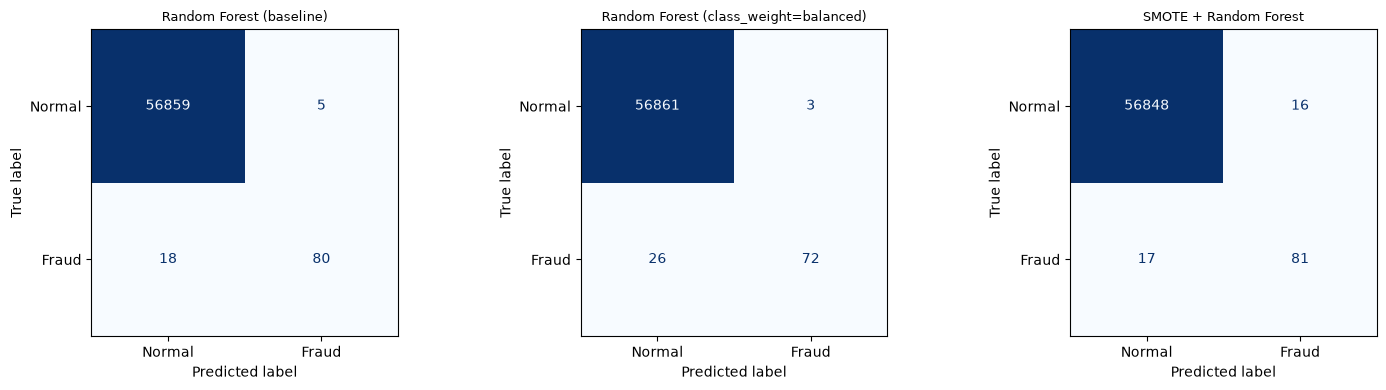


 Random Forest (baseline)
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962


 Random Forest (class_weight=balanced)


              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.96      0.73      0.83        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962


 SMOTE + Random Forest
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.84      0.83      0.83        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [5]:
fig, axes = plt.subplots(1, len(models), figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=['Normal', 'Fraud'],
        cmap='Blues', values_format='d', ax=ax, colorbar=False
    )
    ax.set_title(name, fontsize=9)
plt.tight_layout()
plt.show()

for name, model in models.items():
    print('\n', name)
    print(classification_report(y_test, model.predict(X_test),
                                target_names=['Normal', 'Fraud'], zero_division=0))

## 6. Kesimpulan
Bandingkan recall/precision kelas fraud dan PR-AUC, bukan accuracy semata. SMOTE dapat meningkatkan jumlah fraud yang tertangkap tetapi biasanya menaikkan false positive; class weighting dapat mengubah kompromi tersebut tanpa membuat sampel sintetis. Hasil di atas bergantung pada split acak, fitur, model, dan threshold. Untuk penerapan nyata, gunakan validasi silang yang sesuai, tuning threshold berbasis biaya, dan pemantauan drift.

**Catatan reproduksibilitas:** random state = 42; test set 20% stratified; tidak ada resampling pada test set.